In [42]:
import pandas as pd
import numpy as np
import pickle
from sklearn.metrics import f1_score
from sklearn.metrics import accuracy_score 
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.metrics import classification_report
from sklearn.metrics import precision_score, recall_score
import xgboost as xgb
import matplotlib.pyplot as plt
import seaborn as sns
from model import normalize_record
from sklearn.metrics import mutual_info_score
from sklearn.feature_selection import mutual_info_classif

In [43]:
url = 'https://raw.githubusercontent.com/zm412/machine-learning-zoomcamp/refs/heads/main/midterm/automated_recruitment_analytics.csv'

In [44]:
df = pd.read_csv(url)

In [45]:
df.columns

Index(['Candidate_ID', 'Resume_Text', 'Skills', 'Education',
       'Experience_Years', 'Job_ID', 'Job_Title', 'Required_Skills',
       'Job_Fit_Score', 'Outcome'],
      dtype='str')

In [46]:
df.columns = df.columns.str.lower().str.replace(" ", "_")

In [47]:
df.columns

Index(['candidate_id', 'resume_text', 'skills', 'education',
       'experience_years', 'job_id', 'job_title', 'required_skills',
       'job_fit_score', 'outcome'],
      dtype='str')

***EDA***

1. **Data and missing values:** The dataset contains 2,500 records with **zero missing (null) values**.
2. **Removed identifier and non-predictive columns:**
   * `candidate_id` and `job_id` were dropped because unique identifiers carry no predictive signals.
   * `resume_text` was excluded because its structured information is already extracted into columns (`skills`, `experience_years`, `education`).
   * `job_fit_score` was removed because it represents a pre-computed analytical score rather than a raw candidate/job input feature.
3. **Target and class imbalance:**
   * The original `outcome` column contains three classes: `Rejected`, `Shortlisted`, and `Hired`.
   * For binary classification, `Hired` is encoded as `1` (~11.2% of records) and all other outcomes (`Rejected` and `Shortlisted`) are encoded as `0` (88.8%).
   * Because of this 89/11 class imbalance, models are trained with `class_weight='balanced'`.
4. **Skill parsing:**
   * Raw `skills` and `required_skills` contain comma-separated strings with over 2,300 unique combinations.
   * `collect_unique_skills` extracts individual skill across the dataset (which also populates the frontend UI skill selector).
   * A function, `normalize_record` (located in `model.py` so training and inference share identical transformations), splits skills into individual indicators and pairs `required_skills` with `job_title` (`job__<role>__skill__<skill>`), before encoding all features in `DictVectorizer`.
5. **Feature Importance (`mutual_info_classif`):**
   * Feature importance was evaluated directly on the vectorized training matrix using `mutual_info_classif`.

In [48]:
df['outcome'].value_counts(normalize=True) * 100

outcome
Rejected       49.64
Shortlisted    39.24
Hired          11.12
Name: proportion, dtype: float64

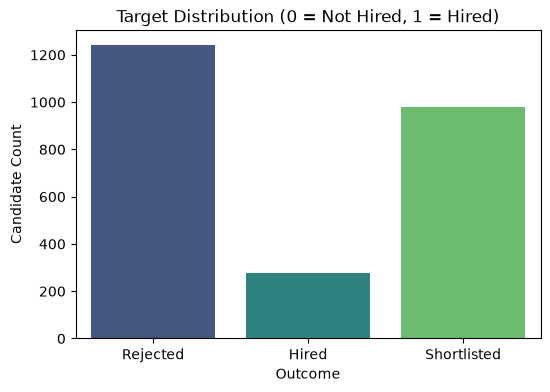

In [49]:
plt.figure(figsize=(6, 4))
sns.countplot(x='outcome', hue='outcome', data=df, palette='viridis', legend=False)
plt.title('Target Distribution (0 = Not Hired, 1 = Hired)')
plt.xlabel('Outcome')
plt.ylabel('Candidate Count')
plt.show()

In [50]:
df['outcome'] = (df['outcome'] == 'Hired').astype(int)

In [51]:
df.columns

Index(['candidate_id', 'resume_text', 'skills', 'education',
       'experience_years', 'job_id', 'job_title', 'required_skills',
       'job_fit_score', 'outcome'],
      dtype='str')

In [52]:
df.head()

,candidate_id,resume_text,skills,education,experience_years,job_id,job_title,required_skills,job_fit_score,outcome
0,CAND00001,Candidate profile: MBA; professional experienc...,"Performance Tuning, Statistics",MBA,1,JOB0103,Web Developer,"Git, JavaScript, CSS, HTML",0.1093,0
1,CAND00002,Aditya is a B.Tech graduate with 10 years of e...,"Kubernetes, Machine Learning, MLOps, Excel, SQ...",B.Tech,10,JOB0088,Machine Learning Engineer,"Machine Learning, MLOps, Python, Deep Learning",1.0000,1
2,CAND00003,Rahul completed B.Sc and has worked for 9 year...,SIEM,B.Sc,9,JOB0158,Cloud Engineer,"Networking, Docker, Linux, Python, AWS",0.3707,0
3,CAND00004,Aditya completed B.E. and has worked for 2 yea...,"PyTorch, Python, Backup and Recovery",B.E.,2,JOB0059,Database Administrator,"PostgreSQL, Linux, Database Design, Performanc...",0.2259,0
4,CAND00005,Manoj has 4 years of professional experience a...,SQL,M.Sc,4,JOB0064,HR Analyst,"HR Analytics, SQL, Power BI, Excel, Communication",0.2679,0


In [53]:
df.isnull().sum()

candidate_id        0
resume_text         0
skills              0
education           0
experience_years    0
job_id              0
job_title           0
required_skills     0
job_fit_score       0
outcome             0
dtype: int64

In [54]:
df.dtypes

candidate_id            str
resume_text             str
skills                  str
education               str
experience_years      int64
job_id                  str
job_title               str
required_skills         str
job_fit_score       float64
outcome               int64
dtype: object

In [55]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
experience_years,2500.0,3.889200,3.078297,0.0,2.0000,3.00000,6.0000,18.0
job_fit_score,2500.0,0.431009,0.197251,0.0,0.2898,0.42205,0.5621,1.0
outcome,2500.0,0.111200,0.314443,0.0,0.0000,0.00000,0.0000,1.0


In [58]:
def collect_unique_skills(series):
  skills_set = set()

  for skills in series.dropna().unique():
    for s in str(skills).split(','):
      cleaned_skill = s.strip().lower()
      if cleaned_skill:
        skills_set.add(cleaned_skill)

  return sorted(list(skills_set))

In [59]:
collect_unique_skills(df['required_skills'])

['accounting',
 'agile',
 'algorithms',
 'apis',
 'aws',
 'backup and recovery',
 'budgeting',
 'communication',
 'css',
 'data structures',
 'data visualization',
 'database design',
 'deep learning',
 'docker',
 'excel',
 'financial modeling',
 'git',
 'hr analytics',
 'html',
 'incident response',
 'java',
 'javascript',
 'kubernetes',
 'linux',
 'machine learning',
 'mlops',
 'networking',
 'pandas',
 'performance tuning',
 'postgresql',
 'power bi',
 'process mapping',
 'project planning',
 'python',
 'pytorch',
 'react',
 'requirements analysis',
 'risk analysis',
 'risk management',
 'security auditing',
 'siem',
 'sql',
 'stakeholder management',
 'statistics']

In [60]:
collect_unique_skills(df['skills'])

['accounting',
 'agile',
 'algorithms',
 'apis',
 'aws',
 'backup and recovery',
 'budgeting',
 'communication',
 'css',
 'data structures',
 'data visualization',
 'database design',
 'deep learning',
 'docker',
 'documentation',
 'excel',
 'financial modeling',
 'git',
 'hr analytics',
 'html',
 'incident response',
 'java',
 'javascript',
 'kubernetes',
 'leadership',
 'linux',
 'machine learning',
 'mlops',
 'networking',
 'pandas',
 'performance tuning',
 'postgresql',
 'power bi',
 'presentation',
 'problem solving',
 'process mapping',
 'project planning',
 'python',
 'pytorch',
 'react',
 'requirements analysis',
 'research',
 'risk analysis',
 'risk management',
 'security auditing',
 'siem',
 'sql',
 'stakeholder management',
 'statistics',
 'teamwork',
 'testing',
 'time management']

In [61]:
del df['candidate_id']
del df['resume_text']
del df['job_fit_score']
del df['job_id']

In [62]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=42)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=42)

df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = df_train['outcome'].values
y_val = df_val['outcome'].values
y_test = df_test['outcome'].values

In [63]:
del df_train['outcome']
del df_val['outcome']
del df_test['outcome']

In [64]:
train_dicts = normalize_record(df_train.to_dict(orient="records"))
val_dicts = normalize_record(df_val.to_dict(orient='records'))

dv = DictVectorizer(sparse=True)
X_train = dv.fit_transform(train_dicts)
X_val = dv.transform(val_dicts)

In [65]:
def feature_evaluation(df, X_train, y_train, dv):
    mi_parsed = mutual_info_classif(X_train, y_train, random_state=42)
    feature_names = dv.get_feature_names_out()

    df_mi = pd.DataFrame({'feature': feature_names, 'mi_score': mi_parsed }).sort_values(by='mi_score', ascending=False)
    plt.figure(figsize=(10, 6))
    sns.barplot(x='mi_score', y='feature', data=df_mi.head(15), color='teal')
    plt.title('Top 15 Parsed Features (Mutual Information)')
    plt.xlabel('Mutual Information Score')
    plt.ylabel('Feature')
    plt.tight_layout()
    plt.show()

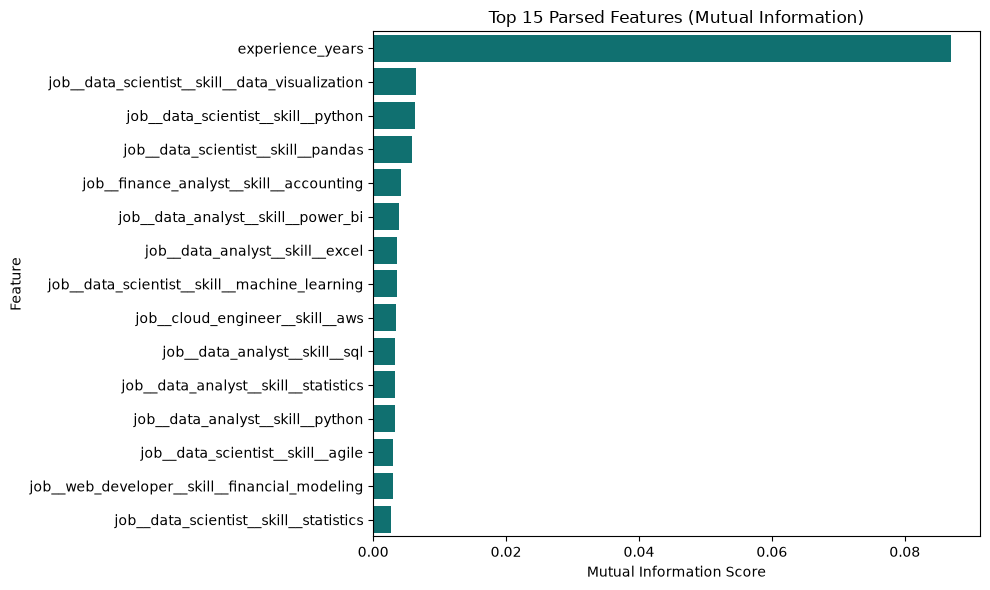

In [66]:
feature_evaluation(df_full_train, X_train, y_train, dv)

In [67]:
dv


DictVectorizer()

### Model Selection, Hyperparameter Tuning & Threshold Optimization

* **Multi-Family Comparison:** Four distinct algorithms spanning linear and tree-based families were trained and evaluated on the validation set using **ROC-AUC** (chosen over raw accuracy due to the 89/11 class imbalance):
  1. **Logistic Regression (`check_best_logistic_auc`):** Tuned inverse regularization strength $C \in \{0.001, 0.01, 0.1, 1.0, 10.0, 100.0\}$ with `class_weight='balanced'`.
  2. **Decision Tree (`check_best_decision_tree_auc`):** Tuned `max_depth` and `min_samples_leaf`.
  3. **Random Forest (`check_best_forest_auc`):** Tuned `n_estimators` and `max_depth` with `class_weight='balanced'`.
  4. **XGBoost (`check_best_xgb_auc`):** Tuned `learning_rate`, `max_depth`, and `n_estimators`.
* **Winning Model:** **Logistic Regression ($C = 1.0$)** achieved the highest validation ROC-AUC.
* **Decision Threshold Tuning:** Sweeping probability thresholds from `0.00` to `1.00` (`research_best_model`) identified the optimal cutoff maximizing **F1-score**, balancing Precision and Recall for the minority `Hired` class before exporting `(dv, model)` to `pipeline.bin`.

In [68]:
def check_best_logistic_auc():
    scores = []

    for c_val in [0.001, 0.01, 0.1, 1.0, 10.0, 100.0]:
        lr_model = LogisticRegression(
            C=c_val,
            max_iter=1000,
            class_weight='balanced',
            random_state=42,
        )
        lr_model.fit(X_train, y_train)

        y_pred = lr_model.predict_proba(X_val)[:, 1]
        auc = roc_auc_score(y_val, y_pred)

        scores.append((c_val, auc, y_pred))

    columns = ['C', 'auc', 'y_pred']
    df_scores = pd.DataFrame(scores, columns=columns)
    best_row = df_scores.loc[df_scores['auc'].idxmax()]

    return best_row

In [69]:
def check_best_decision_tree_auc():
    scores = []

    for depth in [4, 5, 6]:
        for s in [1, 5, 10, 15, 20, 500, 100, 200]:
            dt = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=s)
            dt.fit(X_train, y_train)

            y_pred = dt.predict_proba(X_val)[:, 1]
            auc = roc_auc_score(y_val, y_pred)
            
            scores.append((depth, s, auc, y_pred))
    columns = ['max_depth', 'min_samples_leaf', 'auc', 'y_pred']
    df_scores = pd.DataFrame(scores, columns=columns)
    best_row = df_scores.loc[df_scores['auc'].idxmax()]

    return best_row

In [70]:
def check_best_forest_auc():
    scores = []

    for n in [10, 50, 100, 200]:
        for max_depth in range(10, 201, 10):
            rf = RandomForestClassifier(
              n_estimators=n,
              max_depth=max_depth,
              random_state=42,
              class_weight='balanced',
              n_jobs=-1,
            )
            rf.fit(X_train, y_train)

            y_pred = rf.predict_proba(X_val)[:, 1]
            auc = roc_auc_score(y_val, y_pred)

            scores.append((n, max_depth, auc, y_pred))

    columns = ['n_estimators', 'max_depth', 'auc', 'y_pred']
    df_scores = pd.DataFrame(scores, columns=columns)
    best_row = df_scores.loc[df_scores['auc'].idxmax()]

    return best_row

In [71]:
def check_best_xgb_auc():
    scores = []

    for eta in [0.05, 0.1, 0.3]:
        for max_depth in [3, 5, 10]:
            for n_estimators in [50, 100, 200]:
                xgb_model = xgb.XGBClassifier(
                    learning_rate=eta,
                    max_depth=max_depth,
                    n_estimators=n_estimators,
                    random_state=42,
                    n_jobs=-1,
                )
                xgb_model.fit(X_train, y_train)

                y_pred = xgb_model.predict_proba(X_val)[:, 1]
                auc = roc_auc_score(y_val, y_pred)

                scores.append((eta, max_depth, n_estimators, auc, y_pred))

    columns = ['learning_rate', 'max_depth', 'n_estimators', 'auc', 'y_pred']
    df_scores = pd.DataFrame(scores, columns=columns)
    best_row = df_scores.loc[df_scores['auc'].idxmax()]

    return best_row

In [72]:
def get_comparison_result(best_threshold):
    lr = check_best_logistic_auc()
    dt = check_best_decision_tree_auc()
    rf = check_best_forest_auc()
    xgb = check_best_xgb_auc()

    comparison_df = pd.DataFrame({
        'act': y_val,
        'lr': (lr.y_pred >= best_threshold).astype(int),
        'dt': (dt.y_pred >= best_threshold).astype(int),
        'rf': (rf.y_pred >= best_threshold).astype(int),
        'xgb': (xgb.y_pred >= best_threshold).astype(int),
    })

    return comparison_df

In [73]:
def get_comparison_auc_result():
  lr = check_best_logistic_auc()
  dt = check_best_decision_tree_auc()
  rf = check_best_forest_auc()
  xgb = check_best_xgb_auc()

  comparison_dict = {
      'lr': [lr.auc],
      'dt': [dt.auc],
      'rf': [rf.auc],
      'xgb': [xgb.auc],
  }

  return pd.DataFrame(comparison_dict)

In [74]:
print(get_comparison_auc_result())


         lr        dt        rf      xgb
0  0.923504  0.824807  0.910393  0.91735


In [75]:
check_best_logistic_auc()

C                                                       1.0
auc                                                0.923504
y_pred    [0.0414096777962675, 0.3420482456190373, 0.012...
Name: 3, dtype: object

In [76]:
model = LogisticRegression(C=1.0, max_iter=1000, class_weight='balanced')
model.fit(X_train, y_train)
y_pred = model.predict_proba(X_val)[:, 1]

In [77]:
def research_best_model(y_pred):
    thresholds = np.linspace(0, 1, 101)
    f1_scores = []
    precisions = []
    recalls = []

    for t in thresholds:
        y_pred_bin = (y_pred >= t).astype(int)

        precisions.append(precision_score(y_val, y_pred_bin, zero_division=0))
        recalls.append(recall_score(y_val, y_pred_bin, zero_division=0))

        score = f1_score(y_val, y_pred_bin, zero_division=0)
        f1_scores.append(score)

    best_t_idx = np.argmax(f1_scores)
    best_threshold = thresholds[best_t_idx]
    best_f1 = f1_scores[best_t_idx]
    best_precision = precisions[best_t_idx]
    best_recall = recalls[best_t_idx]

    print(f'Optimal Threshold: {best_threshold:.2f}')
    print(f'F1-Score: {best_f1:.4f}')
    print(f'Precision: {best_precision:.4f}')
    print(f'Recall: {best_recall:.4f}')

    plt.figure(figsize=(10, 6))
    plt.plot(thresholds, precisions, label='Precision', color='blue', linestyle='--')
    plt.plot(thresholds, recalls, label='Recall', color='green', linestyle='--')
    plt.plot(thresholds, f1_scores, label='F1-Score', color='red', linewidth=2)

    plt.axvline(x=best_threshold, color='black', linestyle=':', label=f'Best Threshold ({best_threshold:.2f})',)
    plt.title('Precision, Recall, F1-Score')
    plt.xlabel('Threshold')
    plt.ylabel('Score')
    plt.legend()
    plt.grid(True, alpha=0.3)
    plt.show()

Optimal Threshold: 0.60
F1-Score: 0.6441
Precision: 0.6129
Recall: 0.6786


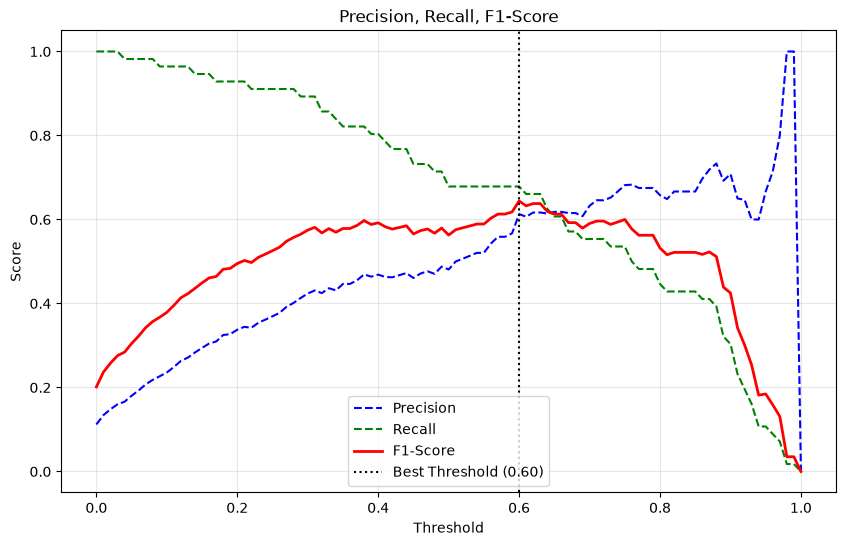

In [78]:
research_best_model(y_pred)

In [79]:
model = LogisticRegression(C=1.0, max_iter=1000, class_weight='balanced')
model.fit(X_train, y_train)
y_pred = model.predict_proba(X_val)[:, 1]